In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from Bio import SeqIO


pep_hits_long = pd.read_csv('long_w_fc_before_z_score_102226.csv')


pep_hits = pd.read_csv('pep_hits__after_FC_AG_z_score_102226.csv')

In [12]:
pep_hits.shape

(829, 22)

In [13]:
lassa = pep_hits_long[pep_hits_long['species'] == 'Mammarenavirus lassaense'].copy()

In [14]:
lassa_hits= pep_hits[pep_hits['species'] == 'Mammarenavirus lassaense'].copy()

In [15]:
lassa_hits[['peptide', 'protein_std']].head(25)

,peptide,protein_std
2,XQN12076.1|polymerase|Mammarenavirus_lassaense...,polymerase
25,WPS90788.1|polymerase|Mammarenavirus_lassaense...,polymerase
26,WPS90786.1|polymerase|Mammarenavirus_lassaense...,polymerase
32,USR47367.1|polymerase|Mammarenavirus_lassaense...,polymerase
39,WJV42629.1|protein|Mammarenavirus_lassaense|G-...,polymerase
41,BBE37069.1|polymerase|Mammarenavirus_lassaense...,polymerase
69,UKY81278.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein
70,UKY81276.1|protein|Mammarenavirus_lassaense|81...,polymerase
71,UKY81272.1|protein|Mammarenavirus_lassaense|81...,polymerase
72,UKY81272.1|protein|Mammarenavirus_lassaense|81...,polymerase


In [16]:
means = (
    lassa.groupby(['protein_std', 'category', 'peptide'])['reactive'].mean().reset_index()
)

top_per_group = means.loc[means.groupby(['protein_std', 'category'])['reactive'].idxmax()].sort_values('reactive', ascending=False)

top_per_group['reactive'] = top_per_group['reactive'].round(4)

top_per_group

,protein_std,category,peptide,reactive
7,glycoprotein,Lassa survivor,AZI96488.1|precursor|Mammarenavirus_lassaense|...,0.3333
15,nucleoprotein,Lassa survivor,ANH09741.1|nucleoprotein|Mammarenavirus_lassae...,0.2333
49,polymerase,Household contact,QBX05734.1|protein|Mammarenavirus_lassaense|LF...,0.2310
91,polymerase,Lassa survivor,QBX05734.1|protein|Mammarenavirus_lassaense|LF...,0.2250
12,nucleoprotein,Household contact,ANH09741.1|nucleoprotein|Mammarenavirus_lassae...,0.1625
3,glycoprotein,Household contact,AZI96488.1|precursor|Mammarenavirus_lassaense|...,0.1083
147,z protein,Household contact,AZI95897.1|protein|Mammarenavirus_lassaense|LA...,0.1047
150,z protein,Lassa survivor,AZI96306.1|protein|Mammarenavirus_lassaense|LA...,0.0667
8,glycoprotein,US healthy,ANH09740.1|precursor|Mammarenavirus_lassaense|...,0.0000
18,nucleoprotein,US healthy,ANH09741.1|nucleoprotein|Mammarenavirus_lassae...,0.0000


In [17]:
lassa.groupby('protein_std')['peptide'].nunique()

protein_std
glycoprotein      4
nucleoprotein     3
polymerase       42
z protein         2
Name: peptide, dtype: int64

In [18]:
lassa['peptide'].nunique()

51

## importing the reference sequences fetched from UniProt (UP000002473_11622.fasta)

In [19]:
records = list(SeqIO.parse('UP000002473_11622_LASV_Josiah_reference.fasta', 'fasta'))

for r in records:
    print(r.id, len(r.seq))

sp|O09705|L_LASSJ 2218
sp|O73557|Z_LASSJ 99
sp|P08669|GLYC_LASSJ 491
sp|P13699|NCAP_LASSJ 569


In [20]:
reference_by_protein = {
    "polymerase": str(next(r.seq for r in records if "O09705" in r.id)),
    "glycoprotein": str(next(r.seq for r in records if "P08669" in r.id)),
    "nucleoprotein": str(next(r.seq for r in records if "P13699" in r.id)),
    "z protein": str(next(r.seq for r in records if "O73557" in r.id)),
}

In [21]:
print(lassa['category'].value_counts())
print(lassa['sequence'].nunique())
print(lassa['protein_std'].unique())

category
Household contact    14127
Lassa survivor        6120
US healthy            4437
Name: count, dtype: int64
51
['polymerase' 'nucleoprotein' 'glycoprotein' 'z protein']


## import PairwiseAligner and use BLOSUM62 matrix for local protein alignment

In [22]:
from Bio.Align import PairwiseAligner
from Bio.Align import substitution_matrices

aligner = PairwiseAligner()
aligner.mode = 'local' #want the peptide to find its best location within the reference

aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

## choose glycoprotein

In [23]:
ref = reference_by_protein['glycoprotein']

np = lassa[lassa['protein_std'].eq("glycoprotein")].copy()

unique_np_peptides = np['sequence'].drop_duplicates()

In [24]:
ref

'MGQIVTFFQEVPHVIEEVMNIVLIALSVLAVLKGLYNFATCGLVGLVTFLLLCGRSCTTSLYKGVYELQTLELNMETLNMTMPLSCTKNNSHHYIMVGNETGLELTLTNTSIINHKFCNLSDAHKKNLYDHALMSIISTFHLSIPNFNQYEAMSCDFNGGKISVQYNLSHSYAGDAANHCGTVANGVLQTFMRMAWGGSYIALDSGRGNWDCIMTSYQYLIIQNTTWEDHCQFSRPSPIGYLGLLSQRTRDIYISRRLLGTFTWTLSDSEGKDTPGGYCLTRWMLIEAELKCFGNTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALINDQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGKTPLGLVDLFVFSTSFYLISIFLHLVKIPTHRHIVGKSCPKPHRLNHMGICSCGLYKQPGVPVKWKR'

## define mapping function

In [25]:
def map_peptide_to_reference(peptide, reference, aligner):
    """
    goal: map a peptide onto a reference protein. 

    output: returns a dictionary containing
    - alignment score
    - reference start/end (1-based)
    - reference positions covered by aligned peptide residues
    """

    #if no exact substring match, use local alignment
    alignment = aligner.align(reference, peptide)[0] #[0] to extract the first and best-scoring Alignment object from the results

    #aligner.align[0].aligned returns the start and end coordinates of the aligned segments for the target and query sequences
    ref_blocks, peptide_blocks = alignment.aligned

    ref_positions = []

    for (ref_start, ref_end), (pep_start, pep_end) in zip(ref_blocks, peptide_blocks):
        
        for i in range(ref_end - ref_start):
            ref_positions.append(ref_start + i + 1) #1-based

    #overall peptide coordinates
    pep_start = peptide_blocks[0][0] + 1
    pep_end = peptide_blocks[-1][1] #take the last block,so -1, in case there are more than one aligned blocks. and [1] for the end

    #total number of peptide residues included in the aligned blocks
    aligned_length = sum(end - start for start, end in peptide_blocks)

    #total number 

    return{
        'score': alignment.score, 
        'ref_start': ref_positions[0],
        'ref_end': ref_positions[-1],
        'ref_positions': ref_positions, 
        'pep_start' : pep_start, 
        'pep_end': pep_end,
        'aligned_length': aligned_length
    }


In [26]:
mapping = []

for peptide in unique_np_peptides:
    result = map_peptide_to_reference(peptide, ref, aligner)

    mapping.append({
        'sequence': peptide, 
        'score': result['score'], 
        'ref_start': result['ref_start'], 
        'ref_end': result['ref_end'], 
        'ref_positions': result['ref_positions'], 
        'pep_start': result['pep_start'], 
        'pep_end': result['pep_end'], 
        'aligned_pep_length': result['aligned_length']

    })

np_mapping = pd.DataFrame(mapping)

In [27]:
#check the length of peptide alignment, should be ~46

np_mapping['alignment_length'] = np_mapping['ref_positions'].str.len()

np_mapping['alignment_length'].describe()

count     4.0
mean     46.0
std       0.0
min      46.0
25%      46.0
50%      46.0
75%      46.0
max      46.0
Name: alignment_length, dtype: float64

In [28]:
np_mapping.sort_values('aligned_pep_length').head(2)

,sequence,score,ref_start,ref_end,ref_positions,pep_start,pep_end,aligned_pep_length,alignment_length
0,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,250.0,347,392,"[347, 348, 349, 350, 351, 352, 353, 354, 355, ...",1,46,46,46
1,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,235.0,369,414,"[369, 370, 371, 372, 373, 374, 375, 376, 377, ...",1,46,46,46


In [29]:
#inspect the shortest mappings: 
np_mapping.sort_values("alignment_length").head(10)

,sequence,score,ref_start,ref_end,ref_positions,pep_start,pep_end,aligned_pep_length,alignment_length
0,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,250.0,347,392,"[347, 348, 349, 350, 351, 352, 353, 354, 355, ...",1,46,46,46
1,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,235.0,369,414,"[369, 370, 371, 372, 373, 374, 375, 376, 377, ...",1,46,46,46
2,YIRAGNNTGLELTLTNTSIISHKFCNLSDAHKKNLYDHTLMSIITT,212.0,94,139,"[94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 1...",1,46,46,46
3,FHLSIPNFNQYEAMSCDFNGGKISIQYNLSHSYAGDAAQHCGTVAN,247.0,140,185,"[140, 141, 142, 143, 144, 145, 146, 147, 148, ...",1,46,46,46


In [30]:
np_mapping = np_mapping.merge(pep_hits[['peptide', 'sensitivity', 'specificity', 'sequence']], on='sequence', how='left')

np_mapping.sort_values('ref_start')[['ref_start', 'ref_end', 'sensitivity', 'peptide', 'sequence']]

,ref_start,ref_end,sensitivity,peptide,sequence
2,94,139,0.055416,ANH09740.1|precursor|Mammarenavirus_lassaense|...,YIRAGNNTGLELTLTNTSIISHKFCNLSDAHKKNLYDHTLMSIITT
3,140,185,0.088161,ANH09740.1|precursor|Mammarenavirus_lassaense|...,FHLSIPNFNQYEAMSCDFNGGKISIQYNLSHSYAGDAAQHCGTVAN
0,347,392,0.176322,AZI96488.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT
1,369,414,0.103275,AZI96059.1|precursor|Mammarenavirus_lassaense|...,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM


## merging the mapping back to the individual-level dataframe


In [31]:
np = np.merge(np_mapping, on='sequence', how='left')

In [32]:
np.shape

(1936, 24)

In [33]:
np.loc[np['reactive']].sort_values(['ref_start', 'rpk'], ascending=[True, False]).head(3)

,peptide_x,individual,z_score,rpk,sequence,species,genus,family,protein_std,accession,...,ref_start,ref_end,ref_positions,pep_start,pep_end,aligned_pep_length,alignment_length,peptide_y,sensitivity,specificity
158,ANH09740.1|precursor|Mammarenavirus_lassaense|...,C-114-3_3_B6,10.470216,10.936813,YIRAGNNTGLELTLTNTSIISHKFCNLSDAHKKNLYDHTLMSIITT,Mammarenavirus lassaense,Mammarenavirus,Arenaviridae,glycoprotein,ANH09740.1,...,94,139,"[94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 1...",1,46,46,46,ANH09740.1|precursor|Mammarenavirus_lassaense|...,0.055416,1.0
822,ANH09740.1|precursor|Mammarenavirus_lassaense|...,C-134-1_2_D7,7.448300,6.219190,YIRAGNNTGLELTLTNTSIISHKFCNLSDAHKKNLYDHTLMSIITT,Mammarenavirus lassaense,Mammarenavirus,Arenaviridae,glycoprotein,ANH09740.1,...,94,139,"[94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 1...",1,46,46,46,ANH09740.1|precursor|Mammarenavirus_lassaense|...,0.055416,1.0
730,ANH09740.1|precursor|Mammarenavirus_lassaense|...,C-110-2_3_F8,5.382763,4.006940,YIRAGNNTGLELTLTNTSIISHKFCNLSDAHKKNLYDHTLMSIITT,Mammarenavirus lassaense,Mammarenavirus,Arenaviridae,glycoprotein,ANH09740.1,...,94,139,"[94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 1...",1,46,46,46,ANH09740.1|precursor|Mammarenavirus_lassaense|...,0.055416,1.0


## .explode() turns one peptide/individual row to one row per amino-acid position covered by that peptide

In [34]:
np_residues = np.explode('ref_positions').rename(columns={'ref_positions': 'position'})

## keep only reactive peptides

In [35]:
reactive_residues = np_residues[np_residues['reactive']].copy()

## now we have the people and amino acid positions at which they have nucleoprotein antibody reactivity. But we need to remove contributions to the same amino-acid position. each individual can contribute at most one to a given amino acid position. 

In [36]:
reactive_residues = reactive_residues[['individual', 'cohort', 'category', 'position']].drop_duplicates()

In [37]:
#reactive_residues['individual'].unique() #no US healthies, as expected

## calculate number of individuals in each category

In [38]:
group_sizes = (
    np[['individual', 'cohort', 'category']].drop_duplicates().groupby(['cohort', 'category']).size().rename('n_individuals').reset_index()
)

group_sizes

,cohort,category,n_individuals
0,HBDB,US healthy,87
1,SL,Household contact,277
2,SL,Lassa survivor,120


## now count reactive individuals at each position

In [39]:
position_counts = (
    reactive_residues.groupby(['cohort', 'category', 'position'])['individual'] #reactive residues only include SL individuals
    .nunique()
    .rename('n_seroreactive')
    .reset_index()
)

position_counts.head(2)

,cohort,category,position,n_seroreactive
0,SL,Household contact,94,16
1,SL,Household contact,95,16


In [40]:
position_summary = position_counts.merge(group_sizes, on=['cohort', 'category'], how='left')

position_summary.head(2)

,cohort,category,position,n_seroreactive,n_individuals
0,SL,Household contact,94,16,277
1,SL,Household contact,95,16,277


In [41]:
position_summary['pct_seroreactive'] = (
    position_summary['n_seroreactive'] / position_summary['n_individuals'] * 100
)

In [42]:
position_summary.head(3)

,cohort,category,position,n_seroreactive,n_individuals,pct_seroreactive
0,SL,Household contact,94,16,277,5.776173
1,SL,Household contact,95,16,277,5.776173
2,SL,Household contact,96,16,277,5.776173


## add positions with zero seroreactivity 

In [43]:
all_positions = pd.DataFrame({'position': range(1, len(ref) + 1)}) #initiate a dataframe with one column

groups = np[['cohort', 'category']].drop_duplicates()

complete_grid = groups.merge(all_positions, how='cross')

complete_grid.head(2)

,cohort,category,position
0,SL,Household contact,1
1,SL,Household contact,2


In [44]:
position_summary = complete_grid.merge(
    position_summary,
    on=["cohort", "category", "position"],
    how="left"
)

position_summary["n_seroreactive"] = (
    position_summary["n_seroreactive"]
    .fillna(0)
)

position_summary = position_summary.drop(columns='n_individuals').merge(group_sizes, on=['cohort', 'category'], how='left')

position_summary['pct_seroreactive'] = 100 * position_summary['n_seroreactive'] / position_summary['n_individuals']

In [45]:
round(position_summary[['pct_seroreactive', 'category']].sort_values(by ='pct_seroreactive',ascending=False).drop_duplicates(),2)

,pct_seroreactive,category
861,37.50,Lassa survivor
846,33.33,Lassa survivor
383,17.69,Household contact
886,15.00,Lassa survivor
347,10.83,Household contact
159,9.03,Household contact
657,8.33,Lassa survivor
408,8.30,Household contact
122,5.78,Household contact
607,5.00,Lassa survivor


In [46]:
position_summary

,cohort,category,position,n_seroreactive,pct_seroreactive,n_individuals
0,SL,Household contact,1,0.0,0.0,277
1,SL,Household contact,2,0.0,0.0,277
2,SL,Household contact,3,0.0,0.0,277
3,SL,Household contact,4,0.0,0.0,277
4,SL,Household contact,5,0.0,0.0,277
...,...,...,...,...,...,...
1468,HBDB,US healthy,487,0.0,0.0,87
1469,HBDB,US healthy,488,0.0,0.0,87
1470,HBDB,US healthy,489,0.0,0.0,87
1471,HBDB,US healthy,490,0.0,0.0,87


## Now going to plot the % of cohort/ category reactive to the amino acid positions of the glycoprotein

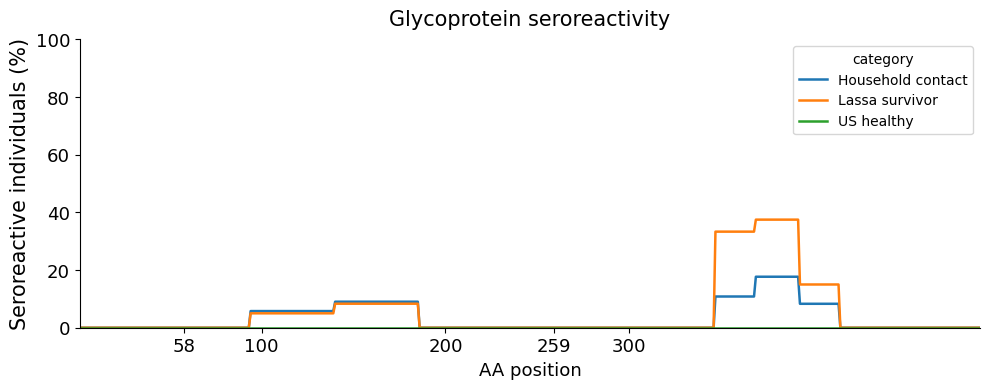

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 4))

sns.lineplot(
    data= position_summary, 
    x='position', 
    y='pct_seroreactive', 
    hue='category', 
    linewidth=1.8, 
    ax=ax
)

ax.set_xlabel('AA position', fontsize=13)
ax.set_ylabel('Seroreactive individuals (%)', fontsize=15)
ax.set_xlim(1, len(ref)) #minimum and maximum position
ax.set_ylim(0,  100)

ax.tick_params(axis='both', labelsize=13)

ax.set_xticks(ticks=[58, 100, 200, 300, 259])

ax.spines['top'].set_visible(False)
ax.spines["right"].set_visible(False)

plt.title('Glycoprotein seroreactivity', y=1.02, fontsize=15)
plt.tight_layout()
plt.rcParams['svg.fonttype'] = 'none'
plt.savefig('glycoprotein_reactivity.svg', format='svg')
plt.show()

## Is there a statistical significance between the categories? 

In [48]:
from scipy.stats import fisher_exact

df = reactive_residues

# who is reactive somewhere in the region
reactive = set(df.loc[df['position'].between(347, 414), 'individual'])

# full roster per category — from your sample metadata, NOT from df
roster = lassa.groupby('individual')[['cohort', 'category']].first().reset_index()
roster['in_region'] = roster['individual'].isin(reactive)

keep = ['Household contact', 'Lassa survivor']          # match your exact labels
sub = roster[roster['category'].isin(keep)]
print(roster['category'].value_counts())

tab = pd.crosstab(sub['category'], sub['in_region'])
print(tab)
print(tab.div(tab.sum(axis=1), axis=0).round(3))
print(fisher_exact(tab.values))

category
Household contact    277
Lassa survivor       120
US healthy            87
Name: count, dtype: int64
in_region          False  True 
category                       
Household contact    228     49
Lassa survivor        75     45
in_region          False  True 
category                       
Household contact  0.823  0.177
Lassa survivor     0.625  0.375
SignificanceResult(statistic=np.float64(2.7918367346938777), pvalue=np.float64(3.47408588589896e-05))


In [49]:
from statsmodels.stats.contingency_tables import Table2x2
t = Table2x2(tab.values)
print(t.oddsratio, t.oddsratio_confint())

2.7918367346938777 (np.float64(1.7249732986011381), np.float64(4.518535075010719))


In [50]:
# everyone reactive in 347–414, with their group
hits = sub.loc[sub['in_region'], ['individual', 'cohort', 'category']]

print(hits['category'].value_counts())      # should be 49 survivors, 55 contacts

# split out
survivors = hits.loc[hits['category'] == 'Lassa survivor', 'individual'].tolist()
contacts  = hits.loc[hits['category'] == 'Household contact', 'individual'].tolist()

category
Household contact    49
Lassa survivor       45
Name: count, dtype: int64


In [51]:
hits.to_csv('reactive_lasv_gp_347_414.csv', index=False)

In [52]:
hits

,individual,cohort,category
2,C-109-3_4_E7,SL,Household contact
8,C-111-3_3_I6,SL,Household contact
9,C-112-1_3_B3,SL,Household contact
13,C-113-3_1_G6,SL,Household contact
14,C-114-1_7_B2,SL,Household contact
...,...,...,...
475,S-506_SA3_H9,SL,Lassa survivor
477,S-508_SA3_H8,SL,Lassa survivor
478,S-509_SA3_H6,SL,Lassa survivor
479,S-510_SA3_D5,SL,Lassa survivor
